# 04 - 2023 DNN, trained federated (step 8)

This notebook **only calls** `baseline_2023.fedtrain`; training lives in `our_work/baseline_2023/fedtrain.py` and was run with
`python -m baseline_2023.fedtrain` (27 runs), which logs to `baseline_2023/results/federated.jsonl`.

**What is trained:** the 2023 DNN (36/35 -> 64 -> 64 -> 32 -> 1) with **FedAvg + a server-side Adam**, exactly as TensorFlow Federated does it in the
authors' notebook: every round each client trains **1 local epoch** (batch 1024, a fresh Adam lr 0.01), the server averages the client weight
**deltas weighted by number of examples** and applies one step of its own persistent Adam (lr 0.05). **100 rounds** (the paper's "epochs 100" are these rounds).
No differential privacy.

**What is NOT done here:** the honest held-out **test set is never used** (step 9). The numbers below are the final-round model scored on the **validation** set
at threshold 0.5. For `as_published` that validation set (the pooled per-client 10% slices) *is* the authors' reported evaluation set, so it can be compared with the paper's Table III.

In [1]:
import sys, pathlib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200, "display.max_columns", 30)
ROOT = pathlib.Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from baseline_2023.fedtrain import load_federated, TABLE_III, MODES, ROUNDS, CLIENT_LR, SERVER_LR, BATCH

rows, hist = load_federated()
df = pd.DataFrame(rows)
print("run", rows[0]["run_id"], "|", len(df), "runs |", "modes", list(df["mode"].unique()), "| clients", sorted(df.n_clients.unique(), reverse=True), "| seeds", sorted(df.seed.unique()))
print(f"{ROUNDS} rounds x 1 local epoch, client Adam {CLIENT_LR}, server Adam {SERVER_LR}, batch {BATCH}; test set used in any run: {bool(df.test_used.any())}")

run 20261127-104159 | 27 runs | modes ['as_published', 'as_published_fixed', 'honest'] | clients [np.int64(15), np.int64(10), np.int64(5)] | seeds [np.int64(0), np.int64(1), np.int64(2)]
100 rounds x 1 local epoch, client Adam 0.01, server Adam 0.05, batch 1024; test set used in any run: False


## What a round looks like (the federation is real)
Per round every client contributes its balanced training rows once. With 15 clients in `as_published` that is **5,493 examples in 15 batches** per round, exactly what the authors' notebook printed
(`num_examples 5493, num_batches 15`). Clients are weighted by their number of examples.

In [2]:
t = df.groupby(["mode", "n_clients"]).agg(inputs=("n_inputs", "first"), examples_per_round=("examples_per_round", "first"),
                                          batches_per_round=("batches_per_round", "first"), min_client_rows=("client_sizes", lambda s: min(s.iloc[0])),
                                          max_client_rows=("client_sizes", lambda s: max(s.iloc[0]))).reset_index()
display(t.sort_values(["mode", "n_clients"], ascending=[True, False]).reset_index(drop=True))
print("authors' notebook: 15 clients 5,493 examples / 15 batches; 10 clients 5,547 / 10; 5 clients 5,586 / 9 (their 10- and 5-client files were made outside the notebook)")

,mode,n_clients,inputs,examples_per_round,batches_per_round,min_client_rows,max_client_rows
0,as_published,15,35,5493,15,246,474
1,as_published,10,35,5562,10,453,663
2,as_published,5,35,5589,9,930,1236
3,as_published_fixed,15,35,5493,15,246,474
4,as_published_fixed,10,35,5562,10,453,663
5,as_published_fixed,5,35,5589,9,930,1236
6,honest,15,36,2782,15,158,212
7,honest,10,36,2782,10,240,324
8,honest,5,36,2782,5,510,602


authors' notebook: 15 clients 5,493 examples / 15 batches; 10 clients 5,547 / 10; 5 clients 5,586 / 9 (their 10- and 5-client files were made outside the notebook)


## Training curves (15 clients)
Training loss is the example-weighted mean over all clients' batches in the round. The model is **lightly trained**: each client takes only 1-2 gradient steps per round.

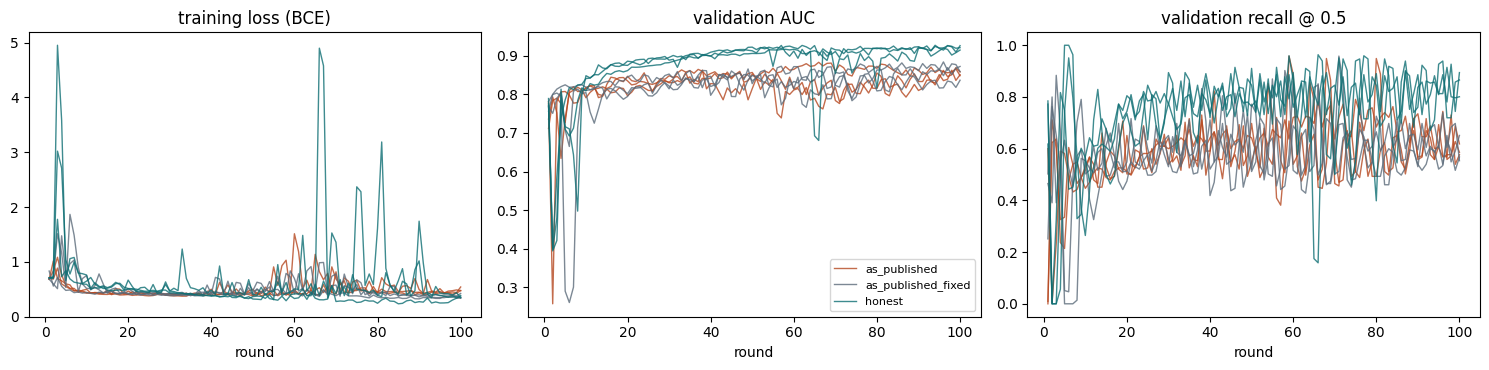

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
col = {"as_published": "#B5471F", "as_published_fixed": "#5B6B7A", "honest": "#0E6E73"}
for m in MODES:
    for s in (0, 1, 2):
        h = hist["runs"][f"{m}|15|{s}"]
        r = np.arange(1, len(h["train_loss"]) + 1)
        kw = dict(color=col[m], alpha=.8, lw=1, label=m if s == 0 else None)
        ax[0].plot(r, h["train_loss"], **kw); ax[1].plot(r, h["val_auc"], **kw); ax[2].plot(r, h["val_rec"], **kw)
ax[0].set_title("training loss (BCE)"); ax[1].set_title("validation AUC"); ax[2].set_title("validation recall @ 0.5")
for a in ax: a.set_xlabel("round")
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

## Final-round results on the validation set (threshold 0.5, mean ± std over 3 seeds)
Always predicting "normal" scores the majority accuracy shown, so accuracy alone says little.

In [4]:
def ms(v, pct=False):
    v = np.asarray(v, dtype=float) * (100 if pct else 1)
    return (f"{v.mean():.2f} ± {v.std(ddof=1):.2f}" if pct else f"{v.mean():.3f} ± {v.std(ddof=1):.3f}")
out = []
for (m, k), g in df.groupby(["mode", "n_clients"]):
    out.append({"mode": m, "clients": k, "inputs": g.n_inputs.iloc[0], "val rows/attacks": f"{g.val_rows.iloc[0]}/{g.val_attacks.iloc[0]}",
                "always-normal acc": round(g.val_majority_acc.iloc[0], 4), "accuracy %": ms(g.final_val_acc, True), "precision %": ms(g.final_val_prec, True),
                "recall %": ms(g.final_val_rec, True), "AUC": ms(g.final_val_auc), "best round (median)": int(g.best_round.median())})
res = pd.DataFrame(out)
res["m"] = res["mode"].map({m: i for i, m in enumerate(MODES)})
display(res.sort_values(["m", "clients"], ascending=[True, False]).drop(columns="m").reset_index(drop=True))

,mode,clients,inputs,val rows/attacks,always-normal acc,accuracy %,precision %,recall %,AUC,best round (median)
0,as_published,15,35,1635/215,0.8685,89.15 ± 2.68,60.69 ± 14.02,59.38 ± 2.20,0.852 ± 0.005,66
1,as_published,10,35,1640/192,0.8829,86.40 ± 5.39,48.23 ± 12.62,75.69 ± 7.82,0.908 ± 0.002,98
2,as_published,5,35,1635/183,0.8881,90.01 ± 2.60,55.68 ± 9.13,69.58 ± 5.79,0.911 ± 0.016,94
3,as_published_fixed,15,35,1635/215,0.8685,89.48 ± 1.08,60.88 ± 6.30,59.07 ± 5.28,0.856 ± 0.018,96
4,as_published_fixed,10,35,1640/192,0.8829,82.72 ± 6.93,40.51 ± 10.10,74.83 ± 8.42,0.904 ± 0.007,87
5,as_published_fixed,5,35,1635/183,0.8881,87.97 ± 2.73,48.61 ± 6.61,75.96 ± 5.46,0.910 ± 0.002,74
6,honest,15,36,1958/246,0.8744,81.34 ± 2.17,39.12 ± 2.79,85.37 ± 4.79,0.920 ± 0.006,62
7,honest,10,36,1958/246,0.8744,75.11 ± 5.99,32.96 ± 4.78,89.70 ± 3.99,0.912 ± 0.005,86
8,honest,5,36,1958/246,0.8744,83.78 ± 6.13,45.55 ± 13.24,81.84 ± 9.70,0.916 ± 0.008,85


## `as_published` against the paper's Table III
The paper's numbers are the authors' notebook output (final round, validation set, threshold 0.5). The authors' own run is unseeded and their 10- and 5-client data files were made outside the notebook, so an **exact** match is not expected.
Run-to-run spread between seeds is shown so the gap can be judged against it.

In [5]:
rows_ = []
for k, (a, p, r) in TABLE_III.items():
    g = df[(df["mode"] == "as_published") & (df.n_clients == k)]
    rows_.append({"clients": k, "paper acc / prec / rec %": f"{a:.2f} / {p:.2f} / {r:.2f}",
                  "ours acc / prec / rec % (mean of 3 seeds)": f"{100*g.final_val_acc.mean():.2f} / {100*g.final_val_prec.mean():.2f} / {100*g.final_val_rec.mean():.2f}",
                  "ours, per-seed recall %": ", ".join(f"{100*x:.1f}" for x in g.sort_values("seed").final_val_rec),
                  "|acc gap| pts": round(abs(100*g.final_val_acc.mean() - a), 2)})
display(pd.DataFrame(rows_))

,clients,paper acc / prec / rec %,ours acc / prec / rec % (mean of 3 seeds),"ours, per-seed recall %",|acc gap| pts
0,15,90.64 / 70.39 / 49.76,89.15 / 60.69 / 59.38,"57.7, 61.9, 58.6",1.49
1,10,91.40 / 65.05 / 61.42,86.40 / 48.23 / 75.69,"83.3, 67.7, 76.0",5.00
2,5,90.70 / 56.40 / 76.63,90.01 / 55.68 / 69.58,"70.5, 63.4, 74.9",0.69


## Effect of the column bug
`as_published` (bug) vs `as_published_fixed` (same data, same pipeline, bug fixed): temperature restored and the row-position input removed.

In [6]:
cmp = df[df["mode"].isin(["as_published", "as_published_fixed"])].groupby(["n_clients", "mode"]).agg(
    acc=("final_val_acc", "mean"), prec=("final_val_prec", "mean"), rec=("final_val_rec", "mean"), auc=("final_val_auc", "mean")).round(3).unstack("mode")
display(cmp.sort_index(ascending=False))

acc                            prec                             rec                             auc                   
mode      as_published as_published_fixed as_published as_published_fixed as_published as_published_fixed as_published as_published_fixed
n_clients                                                                                                                                
15               0.892              0.895        0.607              0.609        0.594              0.591        0.852              0.856
10               0.864              0.827        0.482              0.405        0.757              0.748        0.908              0.904
5                0.900              0.880        0.557              0.486        0.696              0.760        0.911              0.910